
# CA-3: Hotel Booking Cancellation Prediction

Develop and evaluate machine learning models to predict whether a hotel booking will be cancelled using historical hotel booking data.



In [1]:

# Importing the core data analysis libraries
import pandas as pd
import numpy as np

# Importing the visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Importing utilities for file paths and display settings
from pathlib import Path
from IPython.display import display

# Configuring the notebook display
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


In [6]:

# Uploading the hotel booking CSV file
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [7]:
df = pd.read_csv("/content/drive/MyDrive/Raw Dataset/hotel_bookings.csv")
# Loading the dataset
print("Dataset loaded successfully.")


Dataset loaded successfully.


In [51]:

# Inspecting column names and data types
display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Missing Values": df.isna().sum().values,
        "Unique Values": df.nunique(dropna=False).values
    })
)

# Inspecting the dataset structure
#df.info()

,Column,Data Type,Missing Values,Unique Values
0,hotel,object,0,2
1,is_canceled,int64,0,2
2,lead_time,int64,0,479
3,arrival_date_year,int64,0,3
4,arrival_date_month,object,0,12
5,arrival_date_week_number,int64,0,53
6,arrival_date_day_of_month,int64,0,31
7,stays_in_weekend_nights,int64,0,17
8,stays_in_week_nights,int64,0,35
9,adults,int64,0,14


In [52]:
df.shape

(119390, 33)

# EDA

In [53]:
# Checking for duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

# Checking missing values and their percentages
missing_data = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_data = missing_data[missing_data["Missing Values"] > 0]
missing_data = missing_data.sort_values(
    by="Missing Percentage", ascending=False
)

display(missing_data.round(2))

Number of duplicate rows: 31994


,Missing Values,Missing Percentage
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [54]:
# Checking the number of cancelled and non-cancelled bookings
print("Booking cancellation counts:")
display(df["is_canceled"].value_counts())

# Checking the percentage of each target class
print("Booking cancellation percentages:")
display((df["is_canceled"].value_counts(normalize=True) * 100).round(2))


Booking cancellation counts:


,count
is_canceled,
0,75166
1,44224


Booking cancellation percentages:


,proportion
is_canceled,
0,62.96
1,37.04



### Duplicate Record Analysis
This section examines duplicate records and compares their cancellation rates with unique records.


In [55]:

# Identifying duplicated records in the dataset
duplicate_rows = df.duplicated()

print("Unique records:", (~duplicate_rows).sum())
print("Duplicate records:", duplicate_rows.sum())

# Comparing cancellation rates in duplicated and unique records
duplicate_analysis = df.groupby(duplicate_rows)["is_canceled"].agg(
    ["count", "mean"]
)

duplicate_analysis["Cancellation Percentage"] = (
    duplicate_analysis["mean"] * 100
)

display(duplicate_analysis.round(2))


Unique records: 87396
Duplicate records: 31994


,count,mean,Cancellation Percentage
False,87396,0.27,27.49
True,31994,0.63,63.13



### Booking Cancellation Distribution
This section visualises the number of cancelled and non-cancelled bookings.


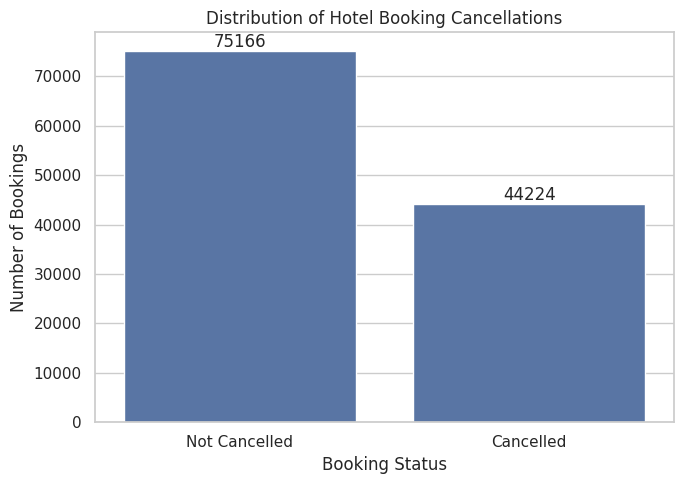

In [56]:
# Counting cancelled and non-cancelled bookings
cancellation_counts = df["is_canceled"].value_counts().sort_index()

# Visualising the cancellation distribution
plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=["Not Cancelled", "Cancelled"],
    y=cancellation_counts.values
)

# Displaying booking counts above each bar
ax.bar_label(
    ax.containers[0]
)

plt.title("Distribution of Hotel Booking Cancellations")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()



### Cancellation Rate by Hotel Type
This section compares booking cancellation rates between city hotels and resort hotels.


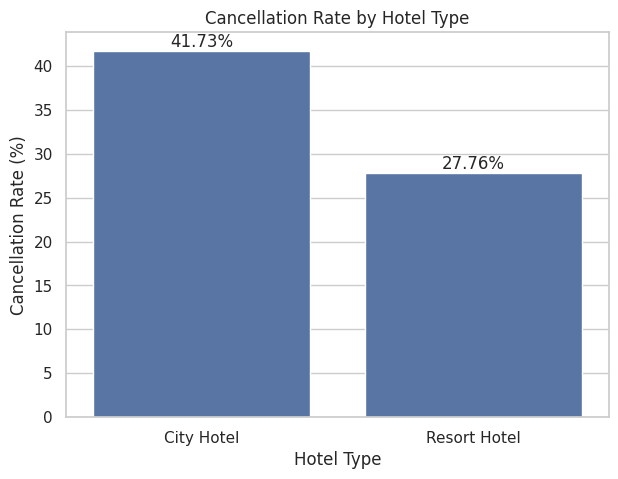

In [57]:

# Calculating cancellation rates by hotel type
hotel_cancellation = df.groupby("hotel")["is_canceled"].mean() * 100

# Visualising cancellation rates by hotel type
plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=hotel_cancellation.index,
    y=hotel_cancellation.values
)

# Displaying cancellation percentages above each bar
ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%"
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.show()


### Cancellation Rate by Market Segment
This section compares booking cancellation rates across different market segments.


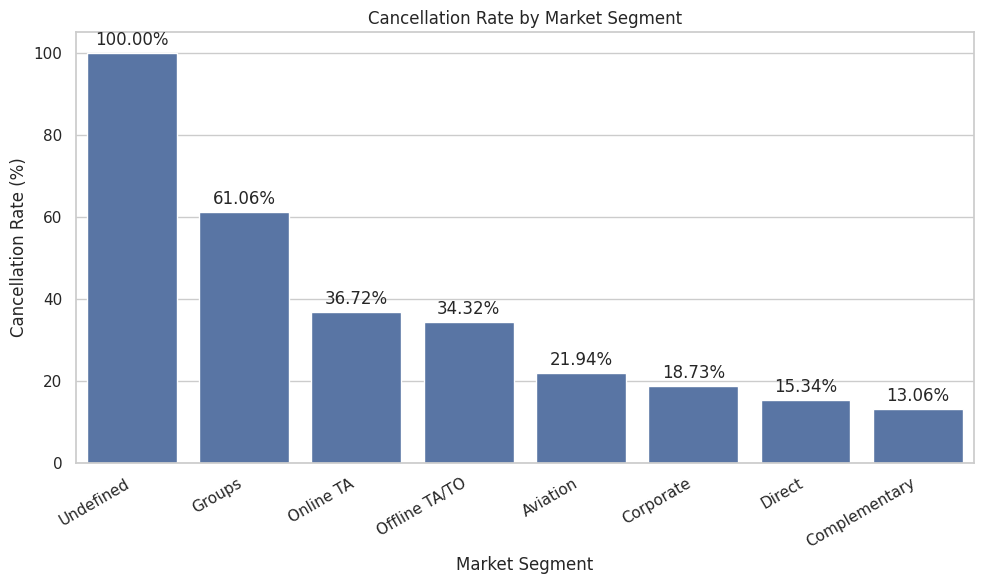

In [58]:
# Calculating cancellation rates across market segments
market_cancellation = (
    df.groupby("market_segment")["is_canceled"].mean() * 100
).sort_values(ascending=False)

# Visualising cancellation rates by market segment
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=market_cancellation.index,
    y=market_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()



### Cancellation Rate by Deposit Type
This section examines how deposit requirements relate to booking cancellations.


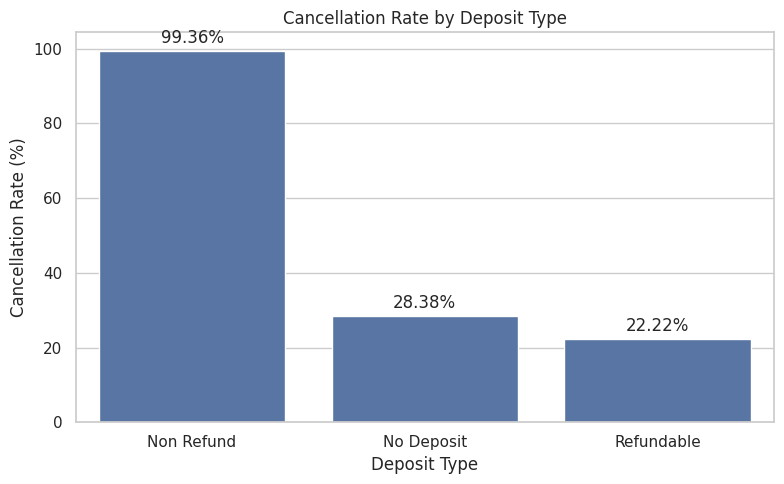

In [59]:
# Calculating cancellation rates by deposit type
deposit_cancellation = (
    df.groupby("deposit_type")["is_canceled"].mean() * 100
).sort_values(ascending=False)

# Visualising cancellation rates by deposit type
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=deposit_cancellation.index,
    y=deposit_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()



### Cancellation Rate by Customer Type
This section compares booking cancellation rates across customer types.


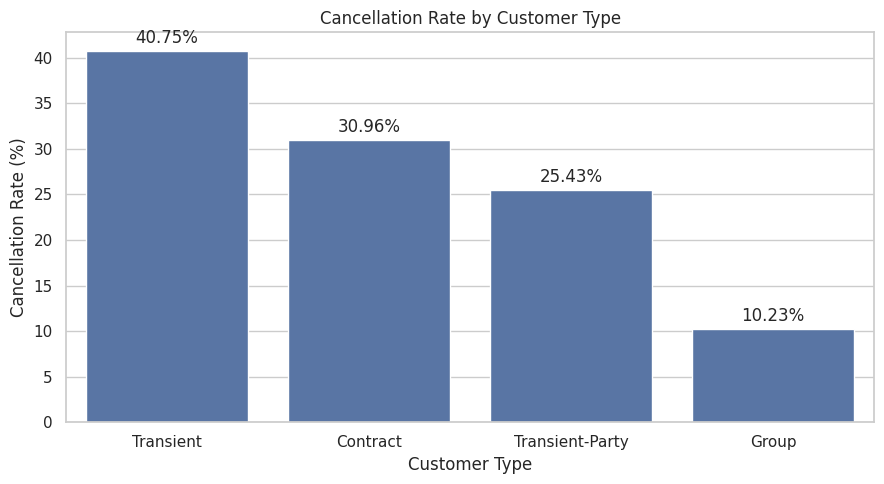

In [60]:
# Calculating cancellation rates by customer type
customer_cancellation = (
    df.groupby("customer_type")["is_canceled"].mean() * 100
).sort_values(ascending=False)

# Visualising cancellation rates by customer type
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=customer_cancellation.index,
    y=customer_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()


### Cancellation Rate by Lead Time
This section compares cancellation rates across booking lead-time groups.


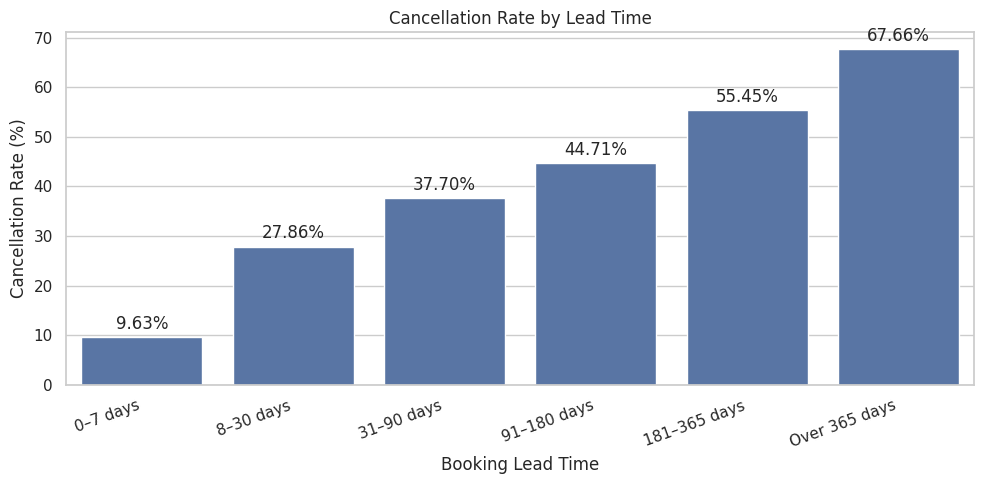

In [61]:
# Grouping bookings by lead time
df["lead_time_group"] = pd.cut(
    df["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, float("inf")],
    labels=[
        "0–7 days",
        "8–30 days",
        "31–90 days",
        "91–180 days",
        "181–365 days",
        "Over 365 days"
    ]
)

# Calculating cancellation rates for each lead-time group
lead_time_cancellation = (
    df.groupby("lead_time_group", observed=False)["is_canceled"].mean() * 100
)

# Visualising cancellation rates by lead-time group
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=lead_time_cancellation.index.astype(str),
    y=lead_time_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Booking Lead Time")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


### Cancellation Rate by Previous Cancellations
This section examines the relationship between previous cancellations and current booking cancellations.


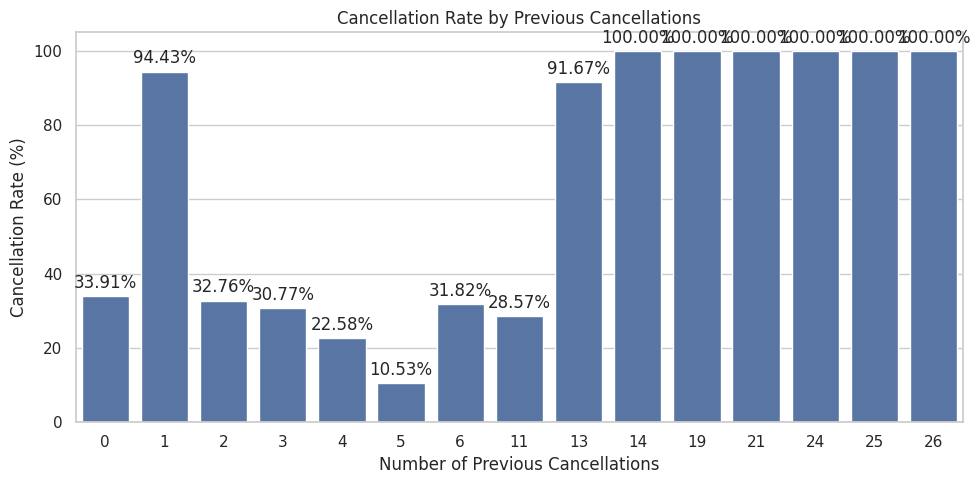

In [62]:

# Grouping bookings by previous cancellation history
previous_cancellation_rate = (
    df.groupby("previous_cancellations")["is_canceled"].mean() * 100
)

# Counting bookings in each previous cancellation group
previous_cancellation_counts = (
    df.groupby("previous_cancellations")["is_canceled"].count()
)

# Combining cancellation rates and booking counts
previous_cancellation_summary = pd.DataFrame({
    "Cancellation Rate (%)": previous_cancellation_rate,
    "Booking Count": previous_cancellation_counts
})

# Visualising cancellation rates by previous cancellations
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=previous_cancellation_rate.index,
    y=previous_cancellation_rate.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Previous Cancellations")
plt.xlabel("Number of Previous Cancellations")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()


### Previous Cancellation History Analysis
This section checks booking counts alongside cancellation rates to identify groups with limited data.


In [63]:

# Summarising booking counts and cancellation rates
previous_cancellation_summary = df.groupby("previous_cancellations")[
    "is_canceled"
].agg(
    Booking_Count="count",
    Cancelled_Bookings="sum",
    Cancellation_Rate="mean"
)

previous_cancellation_summary["Cancellation_Rate"] *= 100

# Displaying the summary for each previous cancellation count
display(previous_cancellation_summary.round(2))


,Booking_Count,Cancelled_Bookings,Cancellation_Rate
previous_cancellations,,,
0,112906,38282,33.91
1,6051,5714,94.43
2,116,38,32.76
3,65,20,30.77
4,31,7,22.58
5,19,2,10.53
6,22,7,31.82
11,35,10,28.57
13,12,11,91.67



### Cancellation Rate by Special Requests
This section compares cancellation rates according to the number of special requests made.


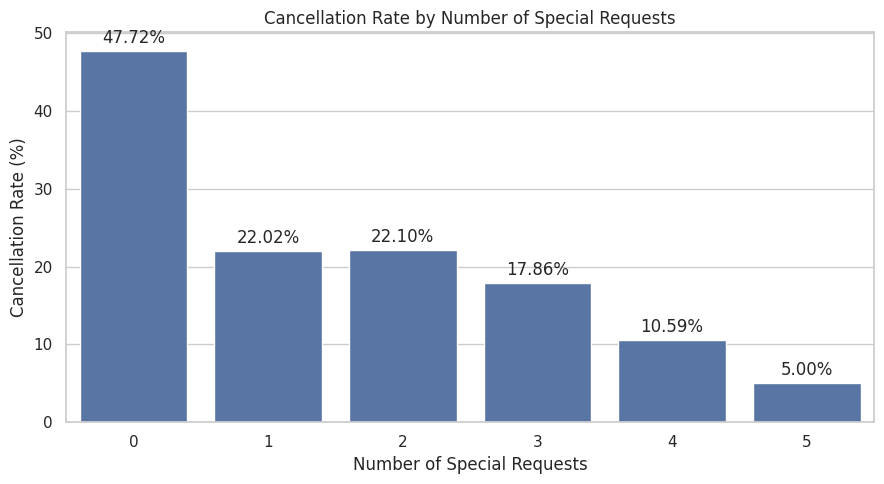

In [64]:

# Calculating cancellation rates by number of special requests
special_request_cancellation = (
    df.groupby("total_of_special_requests")["is_canceled"].mean() * 100
)

# Counting bookings in each special request category
special_request_counts = df.groupby(
    "total_of_special_requests"
)["is_canceled"].count()

# Visualising cancellation rates by special requests
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=special_request_cancellation.index,
    y=special_request_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Number of Special Requests")
plt.xlabel("Number of Special Requests")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

# Displaying cancellation rates and booking counts
special_request_summary = pd.DataFrame({
    "Booking Count": special_request_counts,
    "Cancellation Rate (%)": special_request_cancellation
})



### Cancellation Rate by Arrival Month
This section compares booking cancellation rates across arrival months to identify seasonal patterns.


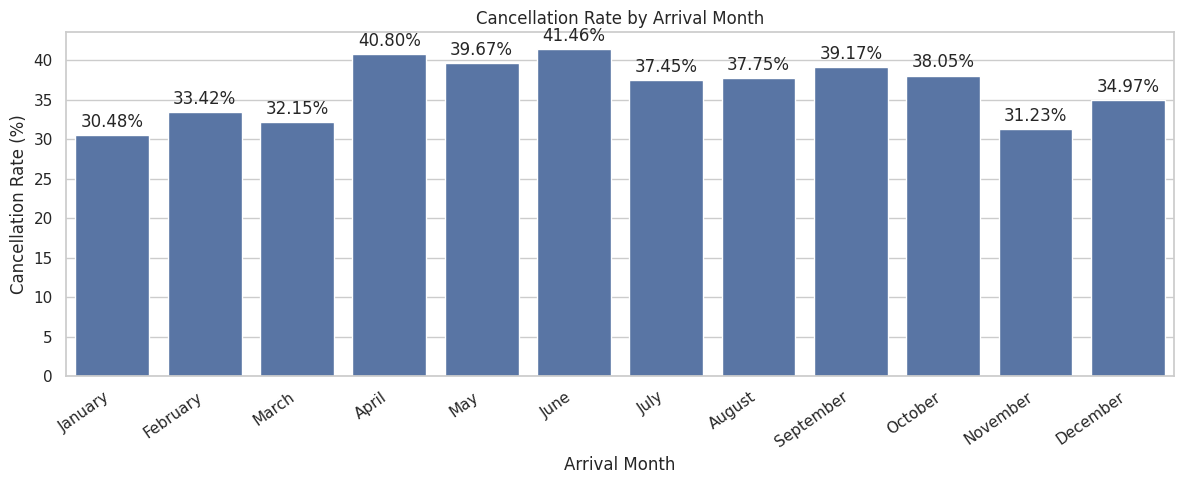

In [65]:

# Defining the calendar order of arrival months
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

# Calculating cancellation rates by arrival month
monthly_cancellation = (
    df.groupby("arrival_date_month")["is_canceled"].mean() * 100
).reindex(month_order)

# Visualising cancellation rates by arrival month
plt.figure(figsize=(12, 5))
ax = sns.barplot(
    x=monthly_cancellation.index,
    y=monthly_cancellation.values,
    order=month_order
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



### Cancellation Rate by Arrival Year
This section compares cancellation rates across the years represented in the dataset.


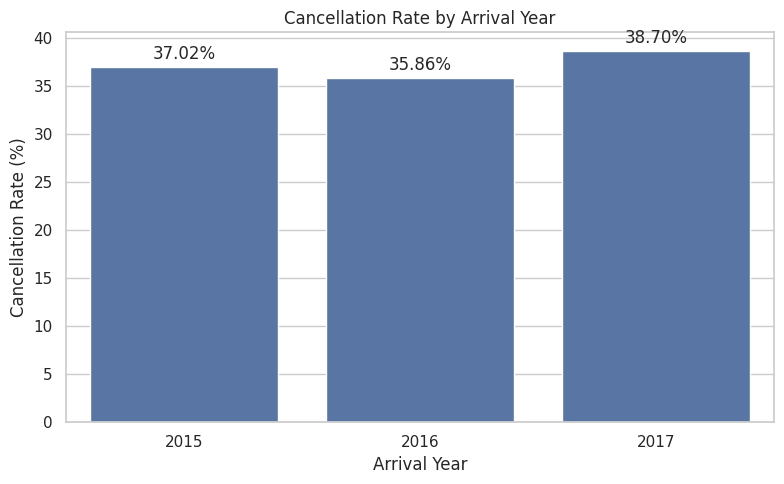

In [66]:

# Calculating cancellation rates by arrival year
yearly_cancellation = (
    df.groupby("arrival_date_year")["is_canceled"].mean() * 100
)

# Visualising cancellation rates by arrival year
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=yearly_cancellation.index.astype(str),
    y=yearly_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Arrival Year")
plt.xlabel("Arrival Year")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()


### Cancellation Rate by Distribution Channel
This section compares booking cancellation rates across distribution channels.


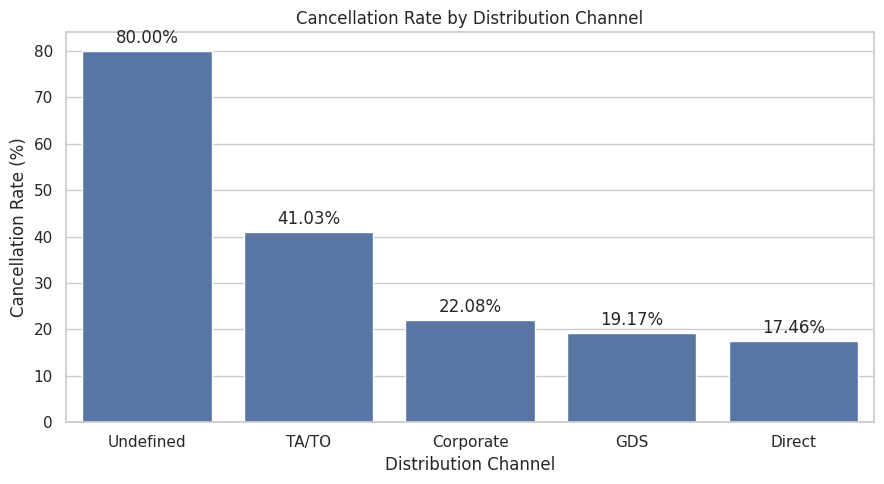

In [67]:
# Calculating cancellation rates by distribution channel
channel_cancellation = (
    df.groupby("distribution_channel")["is_canceled"].mean() * 100
).sort_values(ascending=False)

# Counting bookings in each distribution channel
channel_counts = df.groupby("distribution_channel")["is_canceled"].count()

# Visualising cancellation rates by distribution channel
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=channel_cancellation.index,
    y=channel_cancellation.values
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Cancellation Rate by Distribution Channel")
plt.xlabel("Distribution Channel")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

# Displaying cancellation rates and booking counts
channel_summary = pd.DataFrame({
    "Booking Count": channel_counts,
    "Cancellation Rate (%)": channel_cancellation
})


### Cancellation Rate by Hotel and Customer Type
This section compares cancellation rates across customer types within each hotel category.


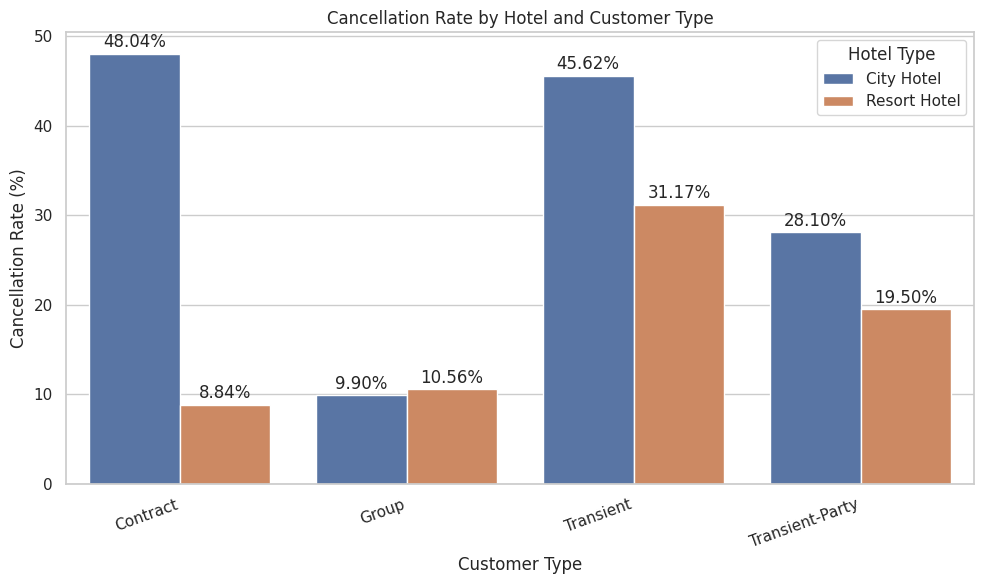

In [68]:
# Calculating cancellation rates by hotel and customer type
hotel_customer_cancellation = (
    df.groupby(["hotel", "customer_type"])["is_canceled"].mean() * 100
).reset_index(name="Cancellation Rate (%)")

# Visualising cancellation rates by hotel and customer type
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=hotel_customer_cancellation,
    x="customer_type",
    y="Cancellation Rate (%)",
    hue="hotel"
)

# Displaying exact cancellation percentages on the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=2)

plt.title("Cancellation Rate by Hotel and Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Hotel Type")
plt.tight_layout()
plt.show()

# Data cleaning and preparation
### Data Quality Review
This section reviews duplicate records, missing values, and target distribution before data cleaning.


In [69]:
# Summarising the current dataset
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

# Reviewing missing values
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

display(
    missing_summary[missing_summary["Missing Values"] > 0]
    .sort_values("Missing Percentage", ascending=False)
    .round(2)
)

# Reviewing the target distribution
target_summary = pd.DataFrame({
    "Booking Count": df["is_canceled"].value_counts().sort_index(),
    "Percentage": (
        df["is_canceled"].value_counts(normalize=True).sort_index() * 100
    )
})

target_summary.index = ["Not Cancelled (0)", "Cancelled (1)"]
display(target_summary.round(2))


Dataset shape: (119390, 33)
Duplicate rows: 31994


,Missing Values,Missing Percentage
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


,Booking Count,Percentage
Not Cancelled (0),75166,62.96
Cancelled (1),44224,37.04



### Duplicate Record Inspection
This section examines duplicate booking records before deciding how to handle them.


In [70]:

# Inspecting duplicate booking records
duplicate_mask = df.duplicated(keep=False)

print("Rows belonging to duplicate groups:", duplicate_mask.sum())

# Displaying sample duplicate records
display(df.loc[duplicate_mask].head(10))

# Comparing duplicate and non-duplicate row counts
print("Duplicate occurrences:", df.duplicated().sum())
print("Unique rows:", (~df.duplicated()).sum())


Rows belonging to duplicate groups: 40165


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,lead_time_group
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03,8–30 days
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03,8–30 days
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07,31–90 days
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07,31–90 days
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.0,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07,31–90 days
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.0,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07,31–90 days
132,Resort Hotel,1,5,2015,July,28,5,1,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01,0–7 days
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01,0–7 days
198,Resort Hotel,0,0,2015,July,28,7,0,1,1,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08,0–7 days
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08,0–7 days


Duplicate occurrences: 31994
Unique rows: 87396



### Target Leakage Review
This section identifies columns that could reveal the booking outcome and distort model performance.


In [71]:

# Reviewing reservation status fields
display(df[["is_canceled", "reservation_status", "reservation_status_date"]].head(10))

# Comparing reservation status with the prediction target
display(pd.crosstab(df["reservation_status"], df["is_canceled"]))


,is_canceled,reservation_status,reservation_status_date
0,0,Check-Out,2015-07-01
1,0,Check-Out,2015-07-01
2,0,Check-Out,2015-07-02
3,0,Check-Out,2015-07-02
4,0,Check-Out,2015-07-03
5,0,Check-Out,2015-07-03
6,0,Check-Out,2015-07-03
7,0,Check-Out,2015-07-03
8,1,Canceled,2015-05-06
9,1,Canceled,2015-04-22


is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207



### Duplicate Record Analysis
This section measures repeated records and checks whether duplicate rows have consistent cancellation outcomes.


In [74]:

# Identifying repeated records across all columns
duplicate_mask = df.duplicated(keep=False)

# Counting rows and distinct records within duplicate groups
duplicate_groups = df.loc[duplicate_mask].drop_duplicates()

print("Rows belonging to duplicate groups:", duplicate_mask.sum())
print("Distinct records in duplicate groups:", len(duplicate_groups))
print("Repeated occurrences after the first copy:", df.duplicated().sum())

# Checking for conflicting cancellation labels among identical features
feature_columns = df.columns.drop("is_canceled")

duplicate_target_check = (
    df.groupby(
        list(feature_columns),
        dropna=False,
        observed=True,
        sort=False
    )["is_canceled"]
    .nunique()
)

print(
    "Feature groups with conflicting cancellation labels:",
    (duplicate_target_check > 1).sum()
)


Rows belonging to duplicate groups: 40165
Distinct records in duplicate groups: 8171
Repeated occurrences after the first copy: 31994
Feature groups with conflicting cancellation labels: 0



### Creating the Modelling Dataset
This section creates a working copy and removes columns that directly reveal the booking outcome.


In [76]:
# Creating a working copy for model preparation
model_df = df.copy()

# Removing outcome-related columns from the modelling dataset
model_df = model_df.drop(
    columns=["reservation_status", "reservation_status_date", "lead_time_group"],
    errors="ignore"
)

# Reviewing the modelling dataset
print("Original dataset shape:", df.shape)
print("Modelling dataset shape:", model_df.shape)
print("Target column retained:", "is_canceled" in model_df.columns)

display(model_df.head())


Original dataset shape: (119390, 33)
Modelling dataset shape: (119390, 30)
Target column retained: True


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1



### Handling Missing Values
This section removes the highly incomplete company feature and fills missing values in the remaining columns.


In [77]:

# Removing the company feature because most values are missing
model_df = model_df.drop(columns=["company"], errors="ignore")

# Filling missing categorical values
model_df["country"] = model_df["country"].fillna("Unknown")
model_df["agent"] = model_df["agent"].fillna(-1)

# Filling missing children values with the median
model_df["children"] = model_df["children"].fillna(
    model_df["children"].median()
)

# Checking missing values after the initial cleaning
print("Remaining missing values:", model_df.isnull().sum().sum())
print("Updated modelling dataset shape:", model_df.shape)

display(
    model_df.isnull().sum()[model_df.isnull().sum() > 0]
)


Remaining missing values: 0
Updated modelling dataset shape: (119390, 29)


,0



### Feature and Target Preparation
This section separates the cancellation target from the predictor features and reviews their data types.


In [78]:
# Separating the prediction target from the input features
X = model_df.drop(columns=["is_canceled"])
y = model_df["is_canceled"]

# Identifying numerical and categorical features
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Number of rows:", len(X))
print("Number of input features:", X.shape[1])
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

# Reviewing the feature data types
display(pd.DataFrame({
    "Feature": X.columns,
    "Data Type": X.dtypes.astype(str).values,
    "Missing Values": X.isnull().sum().values
}))


Number of rows: 119390
Number of input features: 28
Numerical features: 18
Categorical features: 10


,Feature,Data Type,Missing Values
0,hotel,object,0
1,lead_time,int64,0
2,arrival_date_year,int64,0
3,arrival_date_month,object,0
4,arrival_date_week_number,int64,0
5,arrival_date_day_of_month,int64,0
6,stays_in_weekend_nights,int64,0
7,stays_in_week_nights,int64,0
8,adults,int64,0
9,children,float64,0



### Numerical Outlier Inspection
This section reviews numerical ranges and identifies extreme values before deciding whether treatment is necessary.


In [81]:

# Summarising numerical feature distributions
display(X[numerical_features].describe().T.round(2))

# Counting negative values in numerical features
negative_counts = (X[numerical_features] < 0).sum()
display(
    negative_counts[negative_counts > 0]
    .to_frame("Negative Value Count")
)

,count,mean,std,min,25%,50%,75%,max
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119390.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0
is_repeated_guest,119390.0,0.03,0.18,0.00,0.00,0.00,0.0,1.0


,Negative Value Count
agent,16340
adr,1


In [82]:
# Checking extreme values in selected numerical features
for column in ["lead_time", "adr", "adults", "children", "babies"]:
    if column in X.columns:
        print(f"\n{column}:")
        print("Minimum:", X[column].min())
        print("Maximum:", X[column].max())



lead_time:
Minimum: 0
Maximum: 737

adr:
Minimum: -6.38
Maximum: 5400.0

adults:
Minimum: 0
Maximum: 55

children:
Minimum: 0.0
Maximum: 10.0

babies:
Minimum: 0
Maximum: 10



### Stratified Train-Test Split
This section creates training and test sets while preserving the cancellation class distribution.


In [84]:
from sklearn.model_selection import train_test_split


# Splitting the data while preserving the target distribution
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

# Comparing cancellation percentages across the datasets
split_summary = pd.DataFrame({
    "Full Dataset (%)": y.value_counts(normalize=True).sort_index() * 100,
    "Training Set (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Testing Set (%)": y_test.value_counts(normalize=True).sort_index() * 100
})

split_summary.index = ["Not Cancelled", "Cancelled"]
display(split_summary.round(2))


Training feature shape: (95512, 28)
Testing feature shape: (23878, 28)


,Full Dataset (%),Training Set (%),Testing Set (%)
Not Cancelled,62.96,62.96,62.96
Cancelled,37.04,37.04,37.04



### Preparing Features for Machine Learning
This section builds a preprocessing pipeline for numerical and categorical features using training data only.


In [91]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Treating agent as a category rather than a continuous number
X_train = X_train.copy()
X_test = X_test.copy()

X_train["agent"] = X_train["agent"].astype(str)
X_test["agent"] = X_test["agent"].astype(str)

# Identifying numerical and categorical features
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

# Preparing numerical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preparing categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combining numerical and categorical preprocessing
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully.")


Numerical features: 17
Categorical features: 11
Preprocessing pipeline created successfully.



### Model 1: Logistic Regression
Logistic Regression is suitable as a baseline because it is computationally efficient, provides interpretable predictions, and handles binary classification. It helps establish a benchmark for comparing more complex models on the hotel cancellation dataset.


In [92]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score
)

# Creating the logistic regression pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Training the model using the training data
logistic_model.fit(X_train, y_train)

# Predicting cancellation labels and probabilities
y_pred_logistic = logistic_model.predict(X_test)
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Evaluating logistic regression performance
logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_logistic),
    "Precision": precision_score(y_test, y_pred_logistic),
    "Recall": recall_score(y_test, y_pred_logistic),
    "F1 Score": f1_score(y_test, y_pred_logistic),
    "F2 Score": fbeta_score(y_test, y_pred_logistic, beta=2),
    "ROC-AUC": roc_auc_score(y_test, y_prob_logistic)
}

display(pd.DataFrame([logistic_results]).round(4))


,Model,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC-AUC
0,Logistic Regression,0.8289,0.7442,0.82,0.7803,0.8036,0.9129



### Model 2: Random Forest
Random Forest is suitable because it captures nonlinear relationships and interactions between booking features, handles mixed patterns in the data, and reduces overfitting by combining multiple decision trees.


In [93]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score
)

# Creating the Random Forest pipeline
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Training the model
random_forest_model.fit(X_train, y_train)

# Predicting cancellation labels and probabilities
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Evaluating Random Forest performance
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf),
    "Recall": recall_score(y_test, y_pred_rf),
    "F1 Score": f1_score(y_test, y_pred_rf),
    "F2 Score": fbeta_score(y_test, y_pred_rf, beta=2),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf)
}

display(pd.DataFrame([rf_results]).round(4))


,Model,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC-AUC
0,Random Forest,0.8722,0.8185,0.8416,0.8299,0.8369,0.9427



### Initial Model Comparison
This section compares Logistic Regression and Random Forest using the same evaluation metrics.


In [94]:

# Combining the results from both models
model_comparison = pd.DataFrame([
    logistic_results,
    rf_results
])

# Displaying the initial model comparison
display(
    model_comparison.set_index("Model").round(4)
)


,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC-AUC
Model,,,,,,
Logistic Regression,0.8289,0.7442,0.8200,0.7803,0.8036,0.9129
Random Forest,0.8722,0.8185,0.8416,0.8299,0.8369,0.9427



### Model 3: Gradient Boosting
Gradient Boosting is suitable because it builds decision trees sequentially, learning from previous errors to capture complex relationships between booking characteristics and cancellation behaviour.


In [95]:

from sklearn.ensemble import GradientBoostingClassifier

# Creating the Gradient Boosting pipeline
gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.1,
        max_depth=3,
        min_samples_leaf=5,
        random_state=42
    ))
])

# Training the model
gradient_boosting_model.fit(X_train, y_train)

# Predicting cancellation labels and probabilities
y_pred_gb = gradient_boosting_model.predict(X_test)
y_prob_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

# Evaluating Gradient Boosting performance
gb_results = {
    "Model": "Gradient Boosting",
    "Accuracy": accuracy_score(y_test, y_pred_gb),
    "Precision": precision_score(y_test, y_pred_gb),
    "Recall": recall_score(y_test, y_pred_gb),
    "F1 Score": f1_score(y_test, y_pred_gb),
    "F2 Score": fbeta_score(y_test, y_pred_gb, beta=2),
    "ROC-AUC": roc_auc_score(y_test, y_prob_gb)
}

display(pd.DataFrame([gb_results]).round(4))


,Model,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC-AUC
0,Gradient Boosting,0.8593,0.8513,0.7515,0.7983,0.7695,0.9356



### Three-Model Performance Comparison
This section compares the initial performance of Logistic Regression, Random Forest, and Gradient Boosting.


In [96]:

# Combining the results from all three models
model_comparison = pd.DataFrame([
    logistic_results,
    rf_results,
    gb_results
])

# Displaying the three-model comparison
display(model_comparison.set_index("Model").round(4))


,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC-AUC
Model,,,,,,
Logistic Regression,0.8289,0.7442,0.8200,0.7803,0.8036,0.9129
Random Forest,0.8722,0.8185,0.8416,0.8299,0.8369,0.9427
Gradient Boosting,0.8593,0.8513,0.7515,0.7983,0.7695,0.9356



### Comparison of Initial Model Performance
- Random Forest achieved the highest accuracy (87.22%), recall (84.16%), F1 score (0.8299), F2 score (0.8369), and ROC-AUC (0.9427).
- Gradient Boosting achieved the highest precision (85.13%) but had lower recall (75.15%), meaning it missed more actual cancellations.
- Logistic Regression provides a useful baseline, but Random Forest currently offers the best overall balance.
- Cross-validation and hyperparameter tuning will be used before selecting the final model.
